# Project: Investigating No-show Medical Appointments in Brazil

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#eda">Exploratory Data Analysis</a></li>
<li><a href="#conclusions">Conclusions</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Dataset Description 

This data set contains 110,527 appointments and 14 columns. It contains records of medical appointments in Brazil and characteristics associated with those appointments. Each record represents one appointment, not a unique patient, so a patient can appear more than once because they may have multiple appointments. No-show records attendance: "Yes" means missed; "No" means attended. 

Columns:

- PatientId --  Patient identifier; the same patient can appear in multiple appointments.
- AppointmentID -- Unique identifier for each appointment.
- Gender - Recorded gender.
- ScheduledDay -- Date and time when the appointment was booked.
- AppointmentDay -- Date when the appointment was scheduled to take place.
- Age - Patient's age in years.
- Neighbourhood -- Neighborhood where the appointment takes place.
- Scholarship -- Bolsa Familia enrollment indicator.
- Hipertension -- Recorded hypertension indicator.
- Diabetes -- Recorded diabetes indicator.
- Alcoholism -- Recorded alcoholism indicator
- Handcap -- Disability-related code.
- SMS_received -- Recorded SMS indicator.
- No-show -- Attendance outcome.

### Questions for Analysis

1. How does the appointment no-show rate vary across patient age groups?
2. How does the appointment no-show rate differ between records with SMS_received = 1 and SMS_received = 0?
3. How does the appointment no-show rate vary with the number of calendar days between booking and the appointment?


In [1]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



<a id='wrangling'></a>
## Data Wrangling

### General Properties

In [2]:

# Read the CSV into a pandas DataFrame
df = pd.read_csv('noshowappointments-kagglev2-may-2016.csv')

# Display the first five rows for an initial visual inspection.
df.head()


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


In [3]:
# Verify the dataset's dimensions
df.shape

(110527, 14)

In [4]:
#Summarize each column's data type and non-null count.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 17.6 MB


#### Dataset Structure and Data Types

- The dataset has 110527 rows and 14 columns.
- There is no missing values recognized by pandas, however, this doesn't guarantee every value is valid.
- 'ScheduledDay' and 'AppointmenDay'are str. We'll convert them to datetime values during cleaning phase to calculate waiting days.
- PatientID is float64. It's stored numerically, but its role remains identification.
- The other numeric columns are int64. Integer storage doesn't tell us whether a column is binary; we must inspect its values. 

In [5]:
# Check for duplicate appointment records
df.duplicated().sum()

np.int64(0)

In [6]:
# Check whether each row has a unique appointment ID.
df["AppointmentID"].nunique()

110527

#### Duplicate Records and Appointment IDs

- No duplicate rows were found when comparing all 14 columns.
- The dataset contains 110527 unique AppointmentIDs, matching its 110527 rows. No duplicate-record removal is needed.


In [7]:
# Inspect the age distribution for invalid values
df["Age"].describe()

count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

In [8]:
# Count invalid negative ages and examine boundary or unusually high ages

print("Negative ages:", (df["Age"] < 0).sum())
print("Age zero:", (df["Age"] == 0).sum())
print("Ages above 100:", (df["Age"] > 100).sum())

Negative ages: 1
Age zero: 3539
Ages above 100: 7


In [9]:
# Inspect the appointment record with an invalid negative age (-1)

df.loc[df["Age"] < 0]

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
99832,4.659432e+14,5775010,F,2016-06-06T08:58:13Z,2016-06-06T00:00:00Z,-1,ROMÃO,0,0,0,0,0,0,No


In [10]:
# Inspect unusually high ages and their associated identifiers

df.loc[df["Age"] > 100, ['PatientId', 'AppointmentID', "Age"]]

,PatientId,AppointmentID,Age
58014,9.762948e+14,5651757,102
63912,3.196321e+13,5700278,115
63915,3.196321e+13,5700279,115
68127,3.196321e+13,5562812,115
76284,3.196321e+13,5744037,115
90372,2.342836e+11,5751563,102
97666,7.482346e+14,5717451,115


In [11]:
# Count distinct patients associated with appointments with ages above 100

df.loc[df["Age"] > 100, 'PatientId'].nunique()

4

#### Age Validity
- Recorded ages range from -1 to 115 years, with a median of 37.
- One appointment has an invalid negative age.
- There are 3539 appointments with age zero; they may represent infants. 
- Seven appointments have ages above 100, specifically 102 and 115, and belong to four distinct patient IDs.
- The unusually high ages can't be verified from the available data alone. 

In [12]:
# Inspect the recorded SMS category
df["SMS_received"].value_counts(dropna=False)

SMS_received
0    75045
1    35482
Name: count, dtype: int64

In [13]:
# Inspect the attendance category
df["No-show"].value_counts(dropna=False)

No-show
No     88208
Yes    22319
Name: count, dtype: int64

#### Category Validity

- SMS_received contains values of 0 and 1: 75045 appointments have a value of 0, and 35482 have a value of 1.
- No-show contains values of "No" and "Yes": 88208 appointments were attentded, and 22319 were missed. 

#### Assessment Summary

The dataset contains 110,527 appointment records and 14 columns. No missing values or duplicate rows were identified, and every appointment has a unique AppointmentID. SMS_received and No-show contain only their expected categories.

Identified issues and considerations during the assessment:

- Column names need to be corrected and changed to snake case for consistency.
- One record has an invalid age of -1 and requires explicit handling.
- Ages of zero will be retained because they may represent infants. Ages above 100 will also be retained, although their accuracy cannot be independently verified.
- ScheduledDay and AppointmentDay are stored as strings and need to be changed to datetime values.
- Waiting time will be calculated using the date portions of the ScheduledDay and AppointmentDay columns. The resulting intervals will be checked for appointments scheduled before their booking date. 


### Data Cleaning
 

#### Standardizing Column Names
All column names will be standardized to snake_case for consistency. The misspellings will also be corrected. These changes will affect only the column labels.

In [14]:
# Create a working copy of the original DF for cleaning.
df_clean = df.copy()

In [15]:
#Standardize column names to snake_case and correct spelling errors
df_clean = df_clean.rename(columns={
    "PatientId": "patient_id",
    "AppointmentID": "appointment_id",
    "Gender": "gender",
    "ScheduledDay": "scheduled_day",
    "AppointmentDay": "appointment_day",
    "Age": "age",
    "Neighbourhood": "neighborhood",
    "Scholarship": "scholarship",
    "Hipertension": "hypertension",
    "Diabetes": "diabetes",
    "Alcoholism": "alcoholism",
    "Handcap": "handicap",
    "SMS_received": "sms_received",
    "No-show": "no_show"
})
    

In [16]:
# Verify the renamed column labels
df_clean.columns.tolist()

['patient_id',
 'appointment_id',
 'gender',
 'scheduled_day',
 'appointment_day',
 'age',
 'neighborhood',
 'scholarship',
 'hypertension',
 'diabetes',
 'alcoholism',
 'handicap',
 'sms_received',
 'no_show']

#### Handling the Invalid Age

The single negative age will be replaced with a missing value because the correct age is unknown. The appointment record will be retained for analyses using its other valid information.

In [17]:
# Mark the negative age as missing while retaining their appointment records

df_clean.loc[df_clean["age"] < 0, 'age'] = np.nan

In [18]:
# Verify the invalid age was handled and all appointments were retained

print("Negative ages:", (df_clean['age'] < 0).sum())
print("Missing ages:", (df_clean['age'].isna().sum()))
print("Total appointments:", len(df_clean))


Negative ages: 0
Missing ages: 1
Total appointments: 110527


#### Converting Date columns

scheduled_day and appointment_day will be converted from strings to datetime values so they can support date comparisons and waiting-time calculations. Both columns will use UTC.

In [19]:
# Convert booking and appointment timestamps to UTC datetime values

df_clean['scheduled_day'] = pd.to_datetime(
    df_clean['scheduled_day'], errors = 'raise', utc = True)
df_clean['appointment_day'] = pd.to_datetime(
    df_clean['appointment_day'], errors = 'raise', utc = True)

In [20]:
# Verify both columns have datetime data types
df_clean[['scheduled_day', 'appointment_day']].dtypes

scheduled_day      datetime64[us, UTC]
appointment_day    datetime64[us, UTC]
dtype: object

#### Calculating Waiting Days
waiting_days will measure the number of days between scheduled_day and appointment_day. The calculation will exclude time-of-day differences, ensuring that appointments booked for the same calendar date have a waiting time of 0 days. Negative intervals will be inspected before analysis.

In [21]:
# Calculate calendar-day waiting times

df_clean['waiting_days'] = (
    df_clean['appointment_day'].dt.normalize() - df_clean['scheduled_day'].dt.normalize()
        ).dt.days

In [22]:
# Count invalid intervals and preview the calculation

print("Negative waiting times:", (df_clean['waiting_days'] < 0).sum())

df_clean[['scheduled_day', 'appointment_day', 'waiting_days']].head()

Negative waiting times: 5


,scheduled_day,appointment_day,waiting_days
0,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,0
1,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,0
2,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,0
3,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,0
4,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,0


In [23]:
# Inspect appointments dated before their recorded booking dates

df_clean.loc[
    df_clean['waiting_days'] < 0,
    ["appointment_id", "scheduled_day", "appointment_day", "waiting_days"]]

,appointment_id,scheduled_day,appointment_day,waiting_days
27033,5679978,2016-05-10 10:51:53+00:00,2016-05-09 00:00:00+00:00,-1
55226,5715660,2016-05-18 14:50:41+00:00,2016-05-17 00:00:00+00:00,-1
64175,5664962,2016-05-05 13:43:58+00:00,2016-05-04 00:00:00+00:00,-1
71533,5686628,2016-05-11 13:49:20+00:00,2016-05-05 00:00:00+00:00,-6
72362,5655637,2016-05-04 06:50:57+00:00,2016-05-03 00:00:00+00:00,-1


#### Handling Negative Waiting Times
There are five appointment dates earlier than their booking dates: four are -1 day apart, and one is -6 days. Their correct waiting times can't be determined from the available data.

These intervals will be marked as missing and excluded from waiting-time comparisons. The original timestamps and appointment records will be retained. 

In [24]:
# Mark negative waiting intervals as missing
df_clean.loc[df_clean['waiting_days'] < 0, 'waiting_days'] = np.nan

In [25]:
# Verify invalid intervals were handled without removing appointments

print("Negative intervals remaining:", (df_clean['waiting_days'] < 0).sum())
print("Missing waiting times:", df_clean["waiting_days"].isna().sum())
print("Total appointments:", len(df_clean))

Negative intervals remaining: 0
Missing waiting times: 5
Total appointments: 110527


### Cleaning Summary

The cleaned DF still contains 110527 appointment records and 15 columns.
Cleaning and preparation included:

- Standardizing column names to snake_case and correcting spelling errors.
- Replacing the single negative age with a missing value.
- Converting scheduled_day and appointment_day to UTC datetime values.
- Creating waiting_days from the difference between the appointment and booking calendar dates.
- Replacing five negative waiting intervals with missing values.

Ages of zero and above 100 were retained as documented in the assessment. The original DF remains available as a raw-data reference. 

Age-based comparisons will exclude the one record with missing age. Waiting-time comparisons will exclude the five records with missing waiting_days. These exclusion will be applied seperatel, so usable information remains available for other comparisons.

<a id='eda'></a>
## Exploratory Data Analysis


### Overall Attendance Distribution

In [26]:
# Count attended and missed appointments in a consistent order

attendance_counts = (
    df_clean['no_show'].value_counts().reindex(["No", 'Yes']))

In [27]:
# Summarize the attendance counts and percentages

attendance_summary = pd.DataFrame({
    "appointment_count": attendance_counts,
    "percentage": attendance_counts / attendance_counts.sum() * 100
}).rename(index = {"No": "Attend", "Yes": "Missed"})

In [28]:
# Display percentages rounded to two decimal places

attendance_summary.round(2)

,appointment_count,percentage
no_show,,
Attend,88208,79.81
Missed,22319,20.19


## Research Question 1 : How does the no-show rate vary across patient age groups?

In [29]:
# summarize valid recorded ages before defining comparison groups.

df_clean['age'].describe()


count    110526.000000
mean         37.089219
std          23.110026
min           0.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: age, dtype: float64

In [30]:
# Define a reusab;e function for chart titles and axis labels

def label_plot(ax, title, xlabel, ylabel):
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

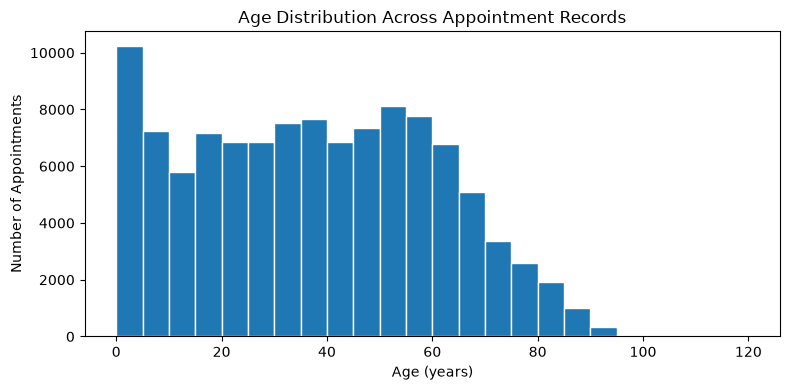

In [31]:
# Plot valid ages using five-year intervals

ax = df_clean['age'].dropna().plot(
    kind = 'hist',
    bins = np.arange(0, 121, 5),
    figsize = (8, 4), 
    edgecolor = 'white')

label_plot(
    ax,
    'Age Distribution Across Appointment Records',
    'Age (years)',
    'Number of Appointments')

plt.tight_layout()
plt.show()

#### Age Distribution

The age histogram shows the highest appointment frequency among recorded ages 0-4, with another peak at ages 50-54. Frequencies generally decline beyond age 60. These statistics describe appointment records rather than unique patients. The distribution provides context for comparing age groups, but does not establish a relationship between age and attendance. 

The selected age groups provide a descriptive comparison between children and adolescents, younger adults, middle-aged adults, and older adults. These boundaries are practical reporting choices rather than established clinical thresholds. Within-group no-show percentages allow comparison despite differences in group sizes. 

In [32]:
# Group valid ages into defined intervals for attendance comparisons. 

df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins = [0, 18, 35, 50, 65, np.inf],
    labels = ['0-17', '18-34', '35-49', '50-64', '65+'],
    right = False)

# Inspect group sizes and confirm the missing age remains unclassified

df_clean['age_group'].value_counts(sort = False, dropna = False)


age_group
0-17     27379
18-34    24246
35-49    21865
50-64    22634
65+      14402
NaN          1
Name: count, dtype: int64

In [33]:
# Count attended and missed appointments within each age group 

age_attendance = pd.crosstab(
    df_clean['age_group'],
    df_clean['no_show'])

# Calculate group totals and missed-appointment percentages

age_summary = pd.DataFrame({
    'total_appointments': age_attendance.sum(axis = 1),
    'missed_appointments': age_attendance['Yes']})

age_summary['no_show_rate'] = ( age_summary["missed_appointments"]
                                    / age_summary['total_appointments'] * 100)

# Display the comparison with percentages rounded to two decimal points

age_summary.round(2)

,total_appointments,missed_appointments,no_show_rate
age_group,,,
0-17,27379,5997,21.90
18-34,24246,5814,23.98
35-49,21865,4490,20.54
50-64,22634,3785,16.72
65+,14402,2233,15.50


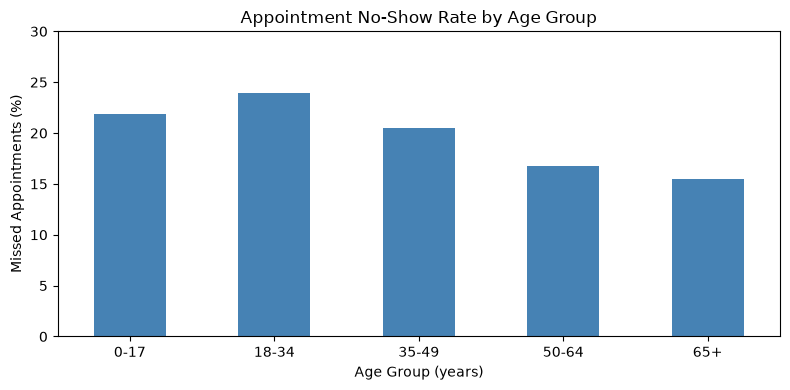

In [34]:
#  Compare missed appointment percentages across age groups

ax = age_summary['no_show_rate'].plot(
    kind = 'bar',
    figsize = (8, 4), 
    rot = 0,
    color = 'steelblue')

label_plot(
    ax,
    'Appointment No-Show Rate by Age Group',
    'Age Group (years)',
    "Missed Appointments (%)")

# Start at zero and leave space above the highest observed rate

ax.set_ylim(0,30)
plt.tight_layout()
plt.show()

### Findings for Question 1

The observed appointment no-show rate varies across the five age groups. Ages 18 - 34 have the highest rate at 23.98%, followed by ages 0-17 at 21.90%. Rates decrease across the older groups older groups: 20.54% for ages 35-49, 16.72% for ages 50 - 64, and 15.50% for ages 65 and above. 

The difference between the highest and lowest rates is approximately 8.48 percentage points. Each rate uses the total appointments within its own age group as the denominator. The comparison includes 110526 appointments, excluding the one record with missing age. 

These results describe an association between age group and attendance within this dataset. They do not establish that age causes missed appointments. The broad age groups may conceal differences within groups. The comparison does not account for other factors such as SMS status or waiting time. 

## Research Question 2:  How does the appointment no-show rate differ between records with SMS_received = 1 and SMS_received = 0?

In [35]:
# count appointments in each recorded SMS category

sms_counts = df_clean['sms_received'].value_counts().reindex([0,1])

# Summarize the category sizes and percentages

sms_distribution = pd.DataFrame({
    'appointment_count': sms_counts,
    'percentage': sms_counts / sms_counts.sum() * 100})

# Display the summary rounded to two decimal places

sms_distribution.round(2)

,appointment_count,percentage
sms_received,,
0,75045,67.9
1,35482,32.1


In [36]:
# Count attendance outcomes within each recorded SMS category

sms_attendance = pd.crosstab(
    df_clean['sms_received'],
    df_clean['no_show'])

#Summarize group totals and missed appointments

sms_summary = pd.DataFrame({
    'total_appointments': sms_attendance.sum(axis = 1),
    'missed_appointments': sms_attendance['Yes']})

# Calculate the missed appointment percentage within each SMS group

sms_summary['no_show_rate'] = (
    sms_summary['missed_appointments'] / sms_summary['total_appointments'] * 100)

sms_summary.round(2)

,total_appointments,missed_appointments,no_show_rate
sms_received,,,
0,75045,12535,16.70
1,35482,9784,27.57


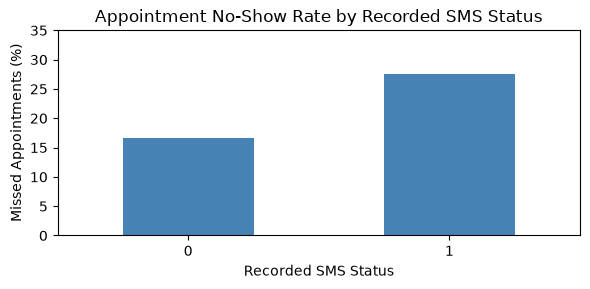

In [37]:
# Compare the no-show percentage across recorded SMS categories

ax = sms_summary['no_show_rate'].plot(
    kind = 'bar',
    figsize = (6, 3),
    rot = 0,
    color = 'steelblue')

label_plot(
    ax,
    'Appointment No-Show Rate by Recorded SMS Status',
    'Recorded SMS Status',
    "Missed Appointments (%)")

ax.set_ylim(0, 35)
plt.tight_layout()
plt.show()

#### Recorded SMS Status And Attendance

Of the 110527 appointment records, 67.90% had recorded SMS status 0 and 32.10% had status 1. The bar chart compares the no show percentages because the two categories contain different numbers of appointments. 

The no show rate was 16.70% for status 0(12535 of 75045 appointments) and 27.57% for status 1 (9784 of 35482 appointments). Status 1 therefore had an observed no show rate 10.87 percentage points higher than status 0. 

This association does not establish that SMS messages caused patients to miss appointments. The groups may differ in waiting time, age or other other characteristics, and this comparison does not adjust for those differences. Recorded SMS status also does not establish whether a patient read the message. 

## Research Question 3: How does the appointment no-show rate vary with waiting time?

Waiting time represents the number of calendar days between booking an appointment and its scheduled date. First, I will examine its distribution, and then compare no-show rates across waiting-time groups.

In [38]:
# Summarize valid waiting times in calendar days

df_clean['waiting_days'].describe()

count    110522.000000
mean         10.184253
std          15.255115
min           0.000000
25%           0.000000
50%           4.000000
75%          15.000000
max         179.000000
Name: waiting_days, dtype: float64

In [39]:
# Group waiting times into ordered calendar-day intervals

df_clean['waiting_group'] = pd.cut(
    df_clean['waiting_days'],
    bins = [0, 1, 8, 15, 31, np.inf],
    labels = ['Same day', '1 -7 days', '8 - 14 days', '15 - 30 days', '31+ days'],
    right = False)

# Check the number of appointments in each group, including missing values

df_clean['waiting_group'].value_counts(sort = False, dropna = False)

waiting_group
Same day        38563
1 -7 days       32185
8 - 14 days     12025
15 - 30 days    17371
31+ days        10378
NaN                 5
Name: count, dtype: int64

In [40]:
# Count attendance outcomes within each waiting-time group

waiting_attendance = pd.crosstab(
    df_clean['waiting_group'],
    df_clean['no_show'])

# Summarie total and missed appointments for each group

waiting_summary = pd.DataFrame({
    'total_appointments': waiting_attendance.sum(axis = 1),
    'missed_appointments': waiting_attendance['Yes']})

# Calculate the percantage of appointments missed within each group

waiting_summary['no_show_rate'] = (
    waiting_summary['missed_appointments'] / waiting_summary['total_appointments'] * 100)

waiting_summary.round(2)

,total_appointments,missed_appointments,no_show_rate
waiting_group,,,
Same day,38563,1792,4.65
1 -7 days,32185,7772,24.15
8 - 14 days,12025,3664,30.47
15 - 30 days,17371,5661,32.59
31+ days,10378,3425,33.00


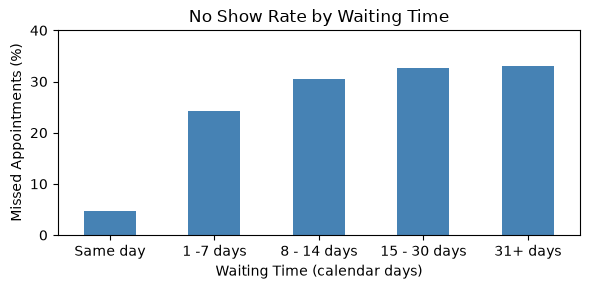

In [41]:
# Compare no-show percentages across waiting time groups

ax = waiting_summary['no_show_rate'].plot(
    kind = 'bar',
    figsize = (6, 3),
    rot = 0,
    color = 'steelblue')

label_plot(
    ax,
    'No Show Rate by Waiting Time',
    'Waiting Time (calendar days)',
    'Missed Appointments (%)'
)

ax.set_ylim(0, 40)
plt.tight_layout()
plt.show()

#### Waiting Time and Attendance

The analysis includes 110522 appointments with valid waiting times; five records with invalid date intervals were excluded from this comparison. The median waiting time was 4 days, compared with a mean of 10.18 days and a maximum of 179 days. 

Same-day appointments were examined separately, while longer waits were grouped using practical week and month boundaries. The bar chart compares percentages because the groups contain different numbers of appointments. 

No-show rates increased across the waiting time groups. 4.65% for same-day appointments. 24.15% for 1 - 7 days, 30.47% for 8-14 days, 32.59% for 15-30 days, and 33.00% for 31+ days. The largest increase occurred between same-day appointments and 1-7-day waits. The difference between the shortest and longest waiting groups was 28.35 percentage points.

Longer-waiting-time groups had higher observed no-show rates, but this doesn't establish causation. The comparison does not adjust for age, recorded SMS status, or other characteristics. Grouping also conceals differences within each interval. 

<a id='conclusions'></a>
## Conclusions

This analysis examined associations between appointment attendance and age, recorded SMS status, and waiting time. Overall, 22319 of 110527 appointments were missed, giving a no-show rate of 20.19%

1. Age: The 18-34 age group had the highest observed no-show rate, at 23.98%, while the 65+ group had the lowest, at 15.50%. Rates declined across successive age groups after the 18-34 group. The difference between the highest and lowest rates was 8.48 percentage points.
2. Recorded SMS status: Appointments with SMS status 1 had a no-show rate of 27.57%, compared with 16.70% for status 0. This 10.87 percentage-point difference doesn't demonstrate that SMS messages caused missed appointments or that reminders were ineffective.
3. Waiting time: No-show rates increased across the selected waiting-time groups, from 4.65% for same-day appointments to 33.00% for waits of 31 days or more. The largest increase occurred between same-day appointments. and waits of 1-7 days.

These findings describe patterns within this dataset. They are tentative associations and don't  establish causal effects or demonstrate how accurately these variables could predict attendance. 

## Limitations

- Separate comparisons: Each explanatory variable was examined separately against attendance. Differences in age, waiting time, recorded SMS status, or other characteristics could contribute to the observed group differences. These comparisons don't isolate the effect of any single factor.
- Repeated patients: Each row represents an appointment, and patients may appear multiple times. The results, therefore, describe appointments rather than unique patients. Patients with more appointments contribute more heavily to the calculated rates.
- Data accuracy: One invalid age was marked as missing and excluded from age-based comparisons. Five invalid waiting intervals were marked as missing and excluded from waiting-time comparisons. Ages above 100 were retained because they couldn't be confirmed as errors, but their accuracy remains uncertain.

## Further Research

A useful next step would be to compare SMS-related no-show rates within the same waiting time groups to investigate whether differences in waiting time contribute to the overall SMS pattern. Future analysis could also examine age and waiting time together and account for repeated appointments by the same patient.

Additional information about SMS timing, message delivery or reading, appointment type, and reasons for nonattendance would help explain the observed patterns. 
